In [1]:
import requests
from bs4 import BeautifulSoup as soup
import lxml.etree as ET
import unicodedata
import pandas as pd

In [39]:
df = pd.read_csv("Kreuzzüge.csv", encoding="utf-8")
df

,idn,titel,author,gnd,year,links
0,1393000940,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
1,1392999154,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
2,1387832093,Die Kreuzzugsbewegung im römisch-deutschen Rei...,"Jaspert, Nikolas",(DE-588)124542115; https://d-nb.info/gnd/12454...,2026,https://doi.org/10.11588/heidok.00037971; http...
3,1388589478,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
4,1388639130,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
...,...,...,...,...,...,...
701,965428664,Geschichte der Kreuzzüge,"Henne am Rhyn, Otto",(DE-588)120474808; https://d-nb.info/gnd/12047...,NaN,NaN
702,974474908,Geschichte der Kreuzzüge,"Waas, Adolf",(DE-588)117075922; https://d-nb.info/gnd/11707...,NaN,https://services.dnb.de/plus/idn/974474908/blurb/
703,550622675,Geschichte der Kreuzzüge nach morgenländischen...,"Wilken, Friedrich",(DE-588)117384259; https://d-nb.info/gnd/11738...,NaN,NaN
704,550987754,Les chroniques de Jherusalem abregies,NaN,NaN,NaN,NaN


In [40]:
df_dates = df.loc[df['year'].notna()].copy()
df_dates

,idn,titel,author,gnd,year,links
0,1393000940,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
1,1392999154,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
2,1387832093,Die Kreuzzugsbewegung im römisch-deutschen Rei...,"Jaspert, Nikolas",(DE-588)124542115; https://d-nb.info/gnd/12454...,2026,https://doi.org/10.11588/heidok.00037971; http...
3,1388589478,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
4,1388639130,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
...,...,...,...,...,...,...
692,720222567,Die Deutschen im Heiligen Lande,"Röhricht, Reinhold",(DE-588)116582456; https://d-nb.info/gnd/11658...,1968,NaN
693,457545666,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1968,https://d-nb.info/457545666/04
694,780166884,Das Imperium christianum und die deutschen Ost...,"Bünding, Margret",NaN,1965,https://d-nb.info/780166884/04
695,453274366,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1965,https://d-nb.info/453274366/04


In [41]:
df_dates.loc[df_dates['year'].str.len() > 4]

,idn,titel,author,gnd,year,links
25,1361481978,Abwesende Hirten,"Tischer, Roman",(DE-588)1252504047; https://d-nb.info/gnd/1252...,[2025],https://services.dnb.de/plus/idn/1361481978/bl...
27,1382778511,Die Aktivität christlicher Orden in Akkon,"Dürrwald, Leonard",NaN,2025; 2025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
28,1382778465,Die Aktivität christlicher Orden in Akkon,"Dürrwald, Leonard",NaN,2025; 2025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
32,1359102744,Die Kreuzzüge,"Troll, Hildebrand",(DE-588)128555696; https://d-nb.info/gnd/12855...,2025; 2025,https://services.dnb.de/plus/idn/1359102744/bl...
37,1359456163,Kreuzfahrer,"Jones, Dan",(DE-588)1070474096; https://d-nb.info/gnd/1070...,2025; [2025],https://services.dnb.de/plus/idn/1359456163/bl...
...,...,...,...,...,...,...
665,760539200,Das Abenteuer der Kreuzzüge,"Frischler, Kurt",(DE-588)104566071X; https://d-nb.info/gnd/1045...,[1976 ?]; [1976 ?]; [1976 ?]; [1976 ?],https://d-nb.info/760539200/04
671,750450614,Der Fall von Akkon,"Stickel, Erwin",NaN,1975; 1975,https://services.dnb.de/plus/idn/750450614/blu...
679,841109699,Die bewaffneten Wallfahrten gen Jerusalem,"Wollschläger, Hans",(DE-588)118771221; https://d-nb.info/gnd/11877...,© 1973,https://services.dnb.de/plus/idn/841109699/blurb/
690,720197147,Die Kreuzfahrer erobern Konstantinopel,Nicetas,(DE-588)118675982; https://d-nb.info/gnd/11867...,[1971],https://d-nb.info/720197147/04


In [50]:
df_dates['year'] = df_dates['year'].str.replace(r'[^0-9]', '', regex=True)
df_dates

,idn,titel,author,gnd,year,links
0,1393000940,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
1,1392999154,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
2,1387832093,Die Kreuzzugsbewegung im römisch-deutschen Rei...,"Jaspert, Nikolas",(DE-588)124542115; https://d-nb.info/gnd/12454...,2026,https://doi.org/10.11588/heidok.00037971; http...
3,1388589478,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
4,1388639130,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
...,...,...,...,...,...,...
692,720222567,Die Deutschen im Heiligen Lande,"Röhricht, Reinhold",(DE-588)116582456; https://d-nb.info/gnd/11658...,1968,NaN
693,457545666,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1968,https://d-nb.info/457545666/04
694,780166884,Das Imperium christianum und die deutschen Ost...,"Bünding, Margret",NaN,1965,https://d-nb.info/780166884/04
695,453274366,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1965,https://d-nb.info/453274366/04


In [51]:
df_dates.loc[df_dates['year'].str.len() > 4]

,idn,titel,author,gnd,year,links
27,1382778511,Die Aktivität christlicher Orden in Akkon,"Dürrwald, Leonard",NaN,20252025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
28,1382778465,Die Aktivität christlicher Orden in Akkon,"Dürrwald, Leonard",NaN,20252025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
32,1359102744,Die Kreuzzüge,"Troll, Hildebrand",(DE-588)128555696; https://d-nb.info/gnd/12855...,20252025,https://services.dnb.de/plus/idn/1359102744/bl...
37,1359456163,Kreuzfahrer,"Jones, Dan",(DE-588)1070474096; https://d-nb.info/gnd/1070...,20252025,https://services.dnb.de/plus/idn/1359456163/bl...
38,138133380X,Kreuzfahrer,"Jones, Dan",(DE-588)1070474096; https://d-nb.info/gnd/1070...,20252025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
39,1381333834,Kreuzfahrer,"Jones, Dan",(DE-588)1070474096; https://d-nb.info/gnd/1070...,20252025,https://nbn-resolving.org/urn:nbn:de:101:1-251...
68,1295824140,Die grausame Geschichte der Kreuzzüge - Der an...,"Krause, Thomas",NaN,20232023,https://nbn-resolving.org/urn:nbn:de:101:1-202...
69,1295824167,Die grausame Geschichte der Kreuzzüge - Der an...,"Krause, Thomas",NaN,20232023,https://nbn-resolving.org/urn:nbn:de:101:1-202...
87,1305719778,Wissen über Ungewisses,"Wallmeyer, Gion",(DE-588)1268939366; https://d-nb.info/gnd/1268...,202320232023,https://doi.org/10.1515/9783111085067; https:/...
88,1286968933,Beiträge zu der Geschichte der Kreuzzüge aus a...,"Petermann, H.",NaN,186020222022,https://doi.org/10.1515/9783112490440; https:/...


In [52]:
df_dates['year'] = df_dates['year'].str[:4]
df_dates

,idn,titel,author,gnd,year,links
0,1393000940,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
1,1392999154,"Die Kreuzzüge neu erzählt: Religion, Land und ...","Winter, Max",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
2,1387832093,Die Kreuzzugsbewegung im römisch-deutschen Rei...,"Jaspert, Nikolas",(DE-588)124542115; https://d-nb.info/gnd/12454...,2026,https://doi.org/10.11588/heidok.00037971; http...
3,1388589478,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
4,1388639130,Heiliger Krieg Traf auf Politische Interessen,"Weiß, Luisa",NaN,2026,https://nbn-resolving.org/urn:nbn:de:101:1-260...
...,...,...,...,...,...,...
692,720222567,Die Deutschen im Heiligen Lande,"Röhricht, Reinhold",(DE-588)116582456; https://d-nb.info/gnd/11658...,1968,NaN
693,457545666,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1968,https://d-nb.info/457545666/04
694,780166884,Das Imperium christianum und die deutschen Ost...,"Bünding, Margret",NaN,1965,https://d-nb.info/780166884/04
695,453274366,Geschichte der Kreuzzüge,"Mayer, Hans Eberhard",(DE-588)120110520; https://d-nb.info/gnd/12011...,1965,https://d-nb.info/453274366/04


In [53]:
df_dates['year'] = df_dates['year'].astype(int)

In [56]:
df_vis = df_dates[['year']].value_counts().reset_index(name='counts')
df_vis

,year,counts
0,2014,30
1,2012,27
2,2023,27
3,2016,24
4,2020,24
...,...,...
56,1990,1
57,1969,1
58,1912,1
59,1860,1


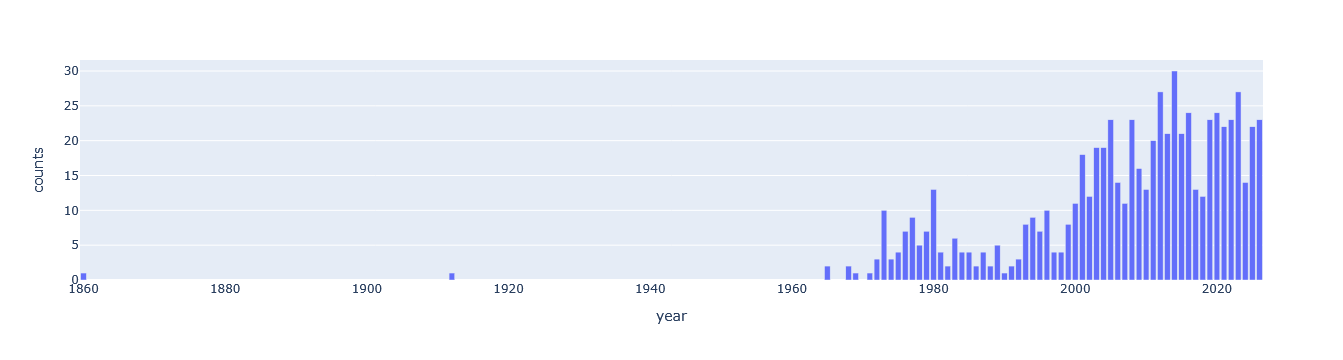

In [58]:
#Mit der Bibliothek plotly können interaktive Graphen geplottet werden:
import plotly.express as px

fig1 = px.bar(df_vis, x='year', y='counts')
fig1.show() #Mit der Funktion .show() wird der fertige Graph angezeigt.

In [61]:
df_authors = df_dates[['author']].value_counts().reset_index(name='counts')
df_authors

,author,counts
0,"Jaspert, Nikolas",23
1,"Mayer, Hans Eberhard",12
2,"Köster-Lösche, Kari",10
3,"Kugler, Bernhard",9
4,"Thorau, Peter",9
...,...,...
321,"Ault-Dumesnil, Edouard de",1
322,"B., Felix",1
323,"Althoff, Gerd",1
324,"Barth, Reinhard",1


In [71]:
df_authors = df_authors.loc[df_authors['counts'] > 5]
df_authors

,author,counts
0,"Jaspert, Nikolas",23
1,"Mayer, Hans Eberhard",12
2,"Köster-Lösche, Kari",10
3,"Kugler, Bernhard",9
4,"Thorau, Peter",9
5,"Milger, Peter",7
6,"Erdmann, Carl",7
7,"Runciman, Steven",7
8,"Erbstößer, Martin",6
9,"Riley-Smith, Jonathan Simon Christopher",6


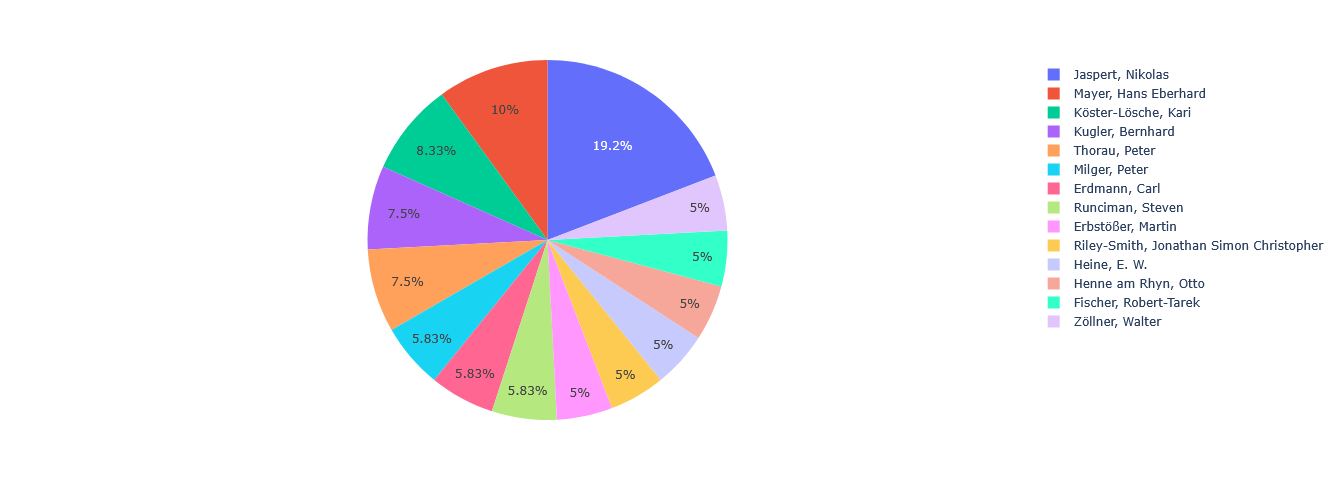

In [74]:
fig2 = px.pie(df_authors, values='counts', names='author', height=500)
#fig2.update_traces(textposition='inside', textinfo='percent+label')
fig2.show() #Mit der Funktion .show() wird der fertige Graph angezeigt.